In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('gdp.csv')
df.head(5)

,Country,Region,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),GDP ($ per capita),Literacy (%),Phones (per 1000),Arable (%),Crops (%),Other (%),Climate,Birthrate,Deathrate,Agriculture,Industry,Service
0,Afghanistan,ASIA (EX. NEAR EAST),31056997,647500,"48,0","0,00","23,06","163,07",700.0,"36,0","3,2","12,13","0,22","87,65",1,"46,6","20,34","0,38","0,24","0,38"
1,Albania,EASTERN EUROPE,3581655,28748,"124,6","1,26","-4,93","21,52",4500.0,"86,5","71,2","21,09","4,42","74,49",3,"15,11","5,22","0,232","0,188","0,579"
2,Algeria,NORTHERN AFRICA,32930091,2381740,"13,8","0,04","-0,39",31,6000.0,"70,0","78,1","3,22","0,25","96,53",1,"17,14","4,61","0,101","0,6","0,298"
3,American Samoa,OCEANIA,57794,199,"290,4","58,29","-20,71","9,27",8000.0,"97,0","259,5",10,15,75,2,"22,46","3,27",NaN,NaN,NaN
4,Andorra,WESTERN EUROPE,71201,468,"152,1","0,00","6,6","4,05",19000.0,"100,0","497,2","2,22",0,"97,78",3,"8,71","6,25",NaN,NaN,NaN


# General Data Overview

In [3]:
#1.	What are the column names in the dataset?
df.columns

Index(['Country', 'Region', 'Population', 'Area (sq. mi.)',
       'Pop. Density (per sq. mi.)', 'Coastline (coast/area ratio)',
       'Net migration', 'Infant mortality (per 1000 births)',
       'GDP ($ per capita)', 'Literacy (%)', 'Phones (per 1000)', 'Arable (%)',
       'Crops (%)', 'Other (%)', 'Climate', 'Birthrate', 'Deathrate',
       'Agriculture', 'Industry', 'Service'],
      dtype='object')

In [4]:
#Many columns in the dataset have long names, we will change them to be shorter

In [5]:
#rename the columns
df.rename(columns={"Area (sq. mi.)": "Area", "Pop. Density (per sq. mi.)":"Pop_Density",
                        "Coastline (coast/area ratio)":"Coastline","Net migration":"Net_migration",
                        "Infant mortality (per 1000 births)":"Infant_mortality","GDP ($ per capita)":"GDP",
                        "Literacy (%)":"Literacy","Phones (per 1000)":"Phones","Arable (%)":"Arable",
                        "Crops (%)":"Crops","Other (%)":"Other"},inplace = True)

df.columns

Index(['Country', 'Region', 'Population', 'Area', 'Pop_Density', 'Coastline',
       'Net_migration', 'Infant_mortality', 'GDP', 'Literacy', 'Phones',
       'Arable', 'Crops', 'Other', 'Climate', 'Birthrate', 'Deathrate',
       'Agriculture', 'Industry', 'Service'],
      dtype='object')

In [6]:
#2.	How many rows and columns are present?
df.shape

(227, 20)

In [7]:
#3.	Are there any missing or null values in the dataset?
df.isnull().sum()

Country              0
Region               0
Population           0
Area                 0
Pop_Density          0
Coastline            0
Net_migration        3
Infant_mortality     3
GDP                  1
Literacy            18
Phones               4
Arable               2
Crops                2
Other                2
Climate             22
Birthrate            3
Deathrate            4
Agriculture         15
Industry            16
Service             15
dtype: int64

In [8]:
# Q5 what are the datatype of each colmn?
#lets check data types of all columns
df.dtypes

Country              object
Region               object
Population            int64
Area                  int64
Pop_Density          object
Coastline            object
Net_migration        object
Infant_mortality     object
GDP                 float64
Literacy             object
Phones               object
Arable               object
Crops                object
Other                object
Climate              object
Birthrate            object
Deathrate            object
Agriculture          object
Industry             object
Service              object
dtype: object

In [9]:
#5.	Which columns have numeric values and which are categorical?

#Numeric and categorical columns:
numeric_columns=df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns=df.select_dtypes(include=['object']).columns

print('Numeric columns:', numeric_columns)
print('Categorical columns:',categorical_columns)

Numeric columns: Index(['Population', 'Area', 'GDP'], dtype='object')
Categorical columns: Index(['Country', 'Region', 'Pop_Density', 'Coastline', 'Net_migration',
       'Infant_mortality', 'Literacy', 'Phones', 'Arable', 'Crops', 'Other',
       'Climate', 'Birthrate', 'Deathrate', 'Agriculture', 'Industry',
       'Service'],
      dtype='object')


In [10]:
#Here'Country' and 'Region' have categorical value, all other columns are numerical values 
#and only 'Population', 'Area', and 'GDP' are float/int type; while the rest (15/20) are identified as object type. 
#We need to convert rest of 15 columns data into float type to continue our data analysis.

for column in df.columns[4:]:
    if 'GDP' not in column: 
        df[column] = df[column].str.replace(',','.').astype(float)

In [11]:
df.dtypes

Country              object
Region               object
Population            int64
Area                  int64
Pop_Density         float64
Coastline           float64
Net_migration       float64
Infant_mortality    float64
GDP                 float64
Literacy            float64
Phones              float64
Arable              float64
Crops               float64
Other               float64
Climate             float64
Birthrate           float64
Deathrate           float64
Agriculture         float64
Industry            float64
Service             float64
dtype: object

# Geographic and Regional Analysis

In [12]:
#6.	How many unique regions are represented in the dataset?
df['Region'].unique()

array(['ASIA (EX. NEAR EAST)         ',
       'EASTERN EUROPE                     ',
       'NORTHERN AFRICA                    ',
       'OCEANIA                            ',
       'WESTERN EUROPE                     ',
       'SUB-SAHARAN AFRICA                 ', 'LATIN AMER. & CARIB    ',
       'C.W. OF IND. STATES ', 'NEAR EAST                          ',
       'NORTHERN AMERICA                   ',
       'BALTICS                            '], dtype=object)

In [13]:
#7.	Which countries belong to each region?
df.groupby('Region')['Country'].apply(list).reset_index()

,Region,Country
0,ASIA (EX. NEAR EAST),"[Afghanistan , Bangladesh , Bhutan , Brunei , ..."
1,BALTICS,"[Estonia , Latvia , Lithuania ]"
2,C.W. OF IND. STATES,"[Armenia , Azerbaijan , Belarus , Georgia , Ka..."
3,EASTERN EUROPE,"[Albania , Bosnia & Herzegovina , Bulgaria , C..."
4,LATIN AMER. & CARIB,"[Anguilla , Antigua & Barbuda , Argentina , Ar..."
5,NEAR EAST,"[Bahrain , Cyprus , Gaza Strip , Iraq , Israel..."
6,NORTHERN AFRICA,"[Algeria , Egypt , Libya , Morocco , Tunisia ,..."
7,NORTHERN AMERICA,"[Bermuda , Canada , Greenland , St Pierre & Mi..."
8,OCEANIA,"[American Samoa , Australia , Cook Islands , F..."
9,SUB-SAHARAN AFRICA,"[Angola , Benin , Botswana , Burkina Faso , Bu..."


In [14]:
#8.	Which region has the highest number of countries?
df['Region'].value_counts().idxmax()

'SUB-SAHARAN AFRICA                 '

In [15]:
#9.	What is the total population per region?
df.groupby('Region')['Population'].sum().reset_index()

,Region,Population
0,ASIA (EX. NEAR EAST),3687982236
1,BALTICS,7184974
2,C.W. OF IND. STATES,280081548
3,EASTERN EUROPE,119914717
4,LATIN AMER. & CARIB,561824599
5,NEAR EAST,195068377
6,NORTHERN AFRICA,161407133
7,NORTHERN AMERICA,331672307
8,OCEANIA,33131662
9,SUB-SAHARAN AFRICA,749437000


In [16]:
#10.	Which region has the largest land area in total?
df.groupby('Region')['Area'].sum().idxmax()

'SUB-SAHARAN AFRICA                 '

# Population and Density

In [17]:
#11.	Which countries have the highest and lowest population?
highest_population=df[df['Population']== df['Population'].max()]
lowest_population=df[df['Population']== df['Population'].min()]
highest_population[['Country','Population']],lowest_population[['Country','Population']]
                                                      

(   Country  Population
 42  China   1313973713,                    Country  Population
 174  St Pierre & Miquelon         7026)

In [18]:
#12.	Which countries have the highest and lowest population density?

highest_pop_density=df[df['Pop_Density']== df['Pop_Density'].max()]
lowest_pop_density=df[df['Pop_Density']== df['Pop_Density'].min()]
highest_pop_density[['Country','Pop_Density']],lowest_pop_density[['Country','Pop_Density']]


(     Country  Pop_Density
 138  Monaco       16271.5,        Country  Pop_Density
 80  Greenland           0.0)

In [19]:
#13.	Is there any country with high population but low density?
df[(df['Population'] > df['Population'].median()) & (df['Pop_Density'] < df['Pop_Density'].median())][['Country','Population','Pop_Density']]

,Country,Population,Pop_Density
0,Afghanistan,31056997,48.0
2,Algeria,32930091,13.8
5,Angola,12127071,9.7
8,Argentina,39921833,14.4
11,Australia,20264082,2.6
18,Belarus,10293011,49.6
21,Benin,7862944,69.8
24,Bolivia,8989046,8.2
27,Brazil,188078227,22.1
30,Bulgaria,7385367,66.6


In [20]:
#14.	Are there countries with similar populations but very different densities?
similar_pop=df.groupby('Population').filter(lambda x: len(x)>1)

similar_pop[['Country','Population','Pop_Density']]


,Country,Population,Pop_Density


# Birth, Death, and Migration

In [21]:
#15.	Which countries have the highest birth rates?
df.sort_values(by='Birthrate', ascending=False)[['Country','Birthrate']].head()


,Country,Birthrate
151,Niger,50.73
128,Mali,49.82
210,Uganda,47.35
0,Afghanistan,46.60
183,Sierra Leone,45.76


In [22]:
#16.	Which countries have the highest death rates?
df.sort_values(by='Deathrate', ascending=False)[['Country','Deathrate']].head()



,Country,Deathrate
194,Swaziland,29.74
26,Botswana,29.50
116,Lesotho,28.71
5,Angola,24.20
117,Liberia,23.10


In [23]:
#17.	Which countries have the highest net migration rates?
df.sort_values(by='Net_migration', ascending=False)[['Country','Net_migration']].head()


,Country,Net_migration
0,Afghanistan,23.06
38,Cayman Islands,18.75
166,Qatar,16.29
111,Kuwait,14.18
208,Turks & Caicos Is,11.68


In [24]:
#18.	Are there any countries with negative net migration?
df[df['Net_migration'] < 0][['Country','Net_migration']].head()

,Country,Net_migration
1,Albania,-4.93
2,Algeria,-0.39
3,American Samoa,-20.71
7,Antigua & Barbuda,-6.15
9,Armenia,-6.47


# Economy and Services

In [25]:
#19.	What is the range of GDP per capita across countries?
df['GDP'].max() , df['GDP'].min()

(55100.0, 500.0)

In [26]:
#20.	Which countries have the highest and lowest GDP per capita?

df.sort_values(by='GDP', ascending=False)[['Country','GDP']].head(2)
df.sort_values(by='GDP')[['Country','GDP']].head(2)



,Country,GDP
58,East Timor,500.0
188,Somalia,500.0


In [27]:
#21.	Are there countries with high GDP but low literacy?
df[(df['GDP'] > df['GDP'].median()) & (df['Literacy'] < df['Literacy'].median())][['Country','GDP','Literacy']].head()

,Country,GDP,Literacy
2,Algeria,6000.0,70.0
7,Antigua & Barbuda,11000.0,89.0
15,Bahrain,16900.0,89.1
26,Botswana,9000.0,79.8
27,Brazil,7600.0,86.4


In [28]:
#22.	Which countries have agriculture as the main contributor to their economy?
df[df['Agriculture'] > df[['Industry','Service']].max(axis=1)][['Country','Agriculture','Industry','Service']].head()

,Country,Agriculture,Industry,Service
32,Burma,0.564,0.082,0.353
33,Burundi,0.463,0.203,0.334
35,Cameroon,0.448,0.170,0.382
39,Central African Rep.,0.550,0.200,0.250
45,"Congo, Dem. Rep.",0.550,0.110,0.340


In [29]:
#23.	Which countries are more service-oriented?
df[df['Service'] > df['Industry']][['Country','Industry','Service']].head()

,Country,Industry,Service
0,Afghanistan,0.240,0.380
1,Albania,0.188,0.579
6,Anguilla,0.180,0.780
7,Antigua & Barbuda,0.220,0.743
8,Argentina,0.358,0.547


# Health and Literacy

In [30]:
#24.Which countries have the highest infant mortality rates?
df.sort_values(by='Infant_mortality', ascending=False)[['Country','Infant_mortality']].head()

,Country,Infant_mortality
5,Angola,191.19
0,Afghanistan,163.07
183,Sierra Leone,143.64
142,Mozambique,130.79
117,Liberia,128.87


In [31]:
#25.Are there countries with low GDP but high literacy rates?
df[(df['GDP'] < df['GDP'].median()) & (df['Literacy'] > df['Literacy'].median())][['Country','GDP','Literacy',]].head()

,Country,GDP,Literacy
9,Armenia,3500.0,98.6
13,Azerbaijan,3400.0,97.0
20,Belize,4900.0,94.1
47,Cook Islands,5000.0,95.0
51,Cuba,2900.0,97.0


In [32]:
#26.Which countries have both high infant mortality and low literacy?
df[(df['Infant_mortality'] > df['Infant_mortality'].median()) & (df['Literacy'] < df['Literacy'].median())][['Country','Infant_mortality','Literacy',]].head()

,Country,Infant_mortality,Literacy
0,Afghanistan,163.07,36.0
1,Albania,21.52,86.5
2,Algeria,31.00,70.0
5,Angola,191.19,42.0
16,Bangladesh,62.60,43.1


In [33]:
#27.What are the literacy rates per region?
df.groupby('Region')['Literacy'].mean()


Region
ASIA (EX. NEAR EAST)                   79.553571
BALTICS                                99.733333
C.W. OF IND. STATES                    98.725000
EASTERN EUROPE                         97.088889
LATIN AMER. & CARIB                    90.654545
NEAR EAST                              79.521429
NORTHERN AFRICA                        67.240000
NORTHERN AMERICA                       97.750000
OCEANIA                                88.835294
SUB-SAHARAN AFRICA                     62.510000
WESTERN EUROPE                         98.391304
Name: Literacy, dtype: float64

# Technology and Communication

In [34]:
#28.	Which countries have the highest phone penetration per 1000 people?

df.sort_values(by='Phones', ascending=False)[['Country','Phones']].head()

,Country,Phones
138,Monaco,1035.6
214,United States,898.0
78,Gibraltar,877.7
22,Bermuda,851.4
85,Guernsey,842.4


In [35]:
#29.	Are there any countries with very low phone penetration?
df.sort_values(by='Phones')[['Country','Phones']].head()

,Country,Phones
45,"Congo, Dem. Rep.",0.2
40,Chad,1.3
151,Niger,1.9
39,Central African Rep.,2.3
117,Liberia,2.3


In [36]:
#30.	Is there a relationship between phone penetration and GDP?
#df[['Phones', 'GDP']].corr()
correlation=df['Phones'].corr(df['GDP'])
print(f"correlation between phone penetration and GDP:{correlation}")

correlation between phone penetration and GDP:0.8344992754140443


# Land Usage and Climate

In [37]:
#31.	Which countries have the highest percentage of arable land?
df.nlargest(10, 'Arable')[['Country','Arable']].head()

,Country,Arable
16,Bangladesh,62.11
211,Ukraine,56.21
137,Moldova,55.30
94,India,54.40
54,Denmark,54.02


In [38]:
#32.	Are there any countries with 0% arable land?

df[df['Arable'] == 0][['Country','Arable']].head()

,Country,Arable
6,Anguilla,0.0
78,Gibraltar,0.0
80,Greenland,0.0
104,Jersey,0.0
122,Macau,0.0


In [39]:
#33.	What climate types exist in the dataset and how many countries are in each?
climate_countries = df.groupby('Climate')['Country'].apply(lambda x: f"{len(x)} countries: {', '.join(x)}")
print(climate_countries)

Climate
1.0    29 countries: Afghanistan , Algeria , Australi...
1.5    8 countries: Bolivia , Cameroon , China , Erit...
2.0    111 countries: American Samoa , Anguilla , Ant...
2.5         3 countries: India , Kyrgyzstan , Swaziland 
3.0    48 countries: Albania , Andorra , Argentina , ...
4.0    6 countries: Armenia , Belarus , Bosnia & Herz...
Name: Country, dtype: object


In [40]:
#34.	Do countries with more arable land tend to have higher birthrates?
correlation=df['Arable'].corr(df['Birthrate'])
print(f"correlation between Arable land and Birthrate:{correlation}")

correlation between Arable land and Birthrate:-0.1868234085985858


# Data Quality and Consistency

In [41]:
#35.	Are there any duplicate rows in the dataset?
df.duplicated().sum()

0

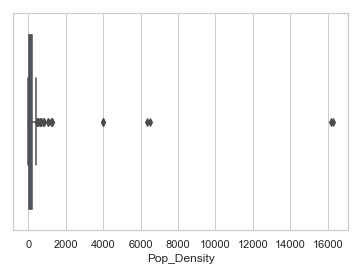

In [52]:
#36.	Are there outliers in any numeric columns (e.g., very high population density)?

sns.boxplot(x=df['Pop_Density'])
plt.show()


In [43]:
#37.	Are the percentage values in "Arable", "Crops", and "Other" columns adding up to 100%?
df['total_percentage'] = df['Arable'] + df['Crops'] + df['Other']
percentage_diff=df['total_percentage']-100
print(percentage_diff.abs().mean())# As it is showing negligible percentage difference

0.0007111111111111591


In [44]:
#38.	Are all country names unique and correctly spelled/formatted?
unique_no_countries=df['Country'].nunique()
unique_name_countries=df['Country'].unique()
print('unique no of countries:',unique_no_countries)
print('unique name of countries:',unique_name_countries)#yes it is correctly formatted

unique no of countries: 227
unique name of countries: ['Afghanistan ' 'Albania ' 'Algeria ' 'American Samoa ' 'Andorra '
 'Angola ' 'Anguilla ' 'Antigua & Barbuda ' 'Argentina ' 'Armenia '
 'Aruba ' 'Australia ' 'Austria ' 'Azerbaijan ' 'Bahamas, The ' 'Bahrain '
 'Bangladesh ' 'Barbados ' 'Belarus ' 'Belgium ' 'Belize ' 'Benin '
 'Bermuda ' 'Bhutan ' 'Bolivia ' 'Bosnia & Herzegovina ' 'Botswana '
 'Brazil ' 'British Virgin Is. ' 'Brunei ' 'Bulgaria ' 'Burkina Faso '
 'Burma ' 'Burundi ' 'Cambodia ' 'Cameroon ' 'Canada ' 'Cape Verde '
 'Cayman Islands ' 'Central African Rep. ' 'Chad ' 'Chile ' 'China '
 'Colombia ' 'Comoros ' 'Congo, Dem. Rep. ' 'Congo, Repub. of the '
 'Cook Islands ' 'Costa Rica ' "Cote d'Ivoire " 'Croatia ' 'Cuba '
 'Cyprus ' 'Czech Republic ' 'Denmark ' 'Djibouti ' 'Dominica '
 'Dominican Republic ' 'East Timor ' 'Ecuador ' 'Egypt ' 'El Salvador '
 'Equatorial Guinea ' 'Eritrea ' 'Estonia ' 'Ethiopia ' 'Faroe Islands '
 'Fiji ' 'Finland ' 'France ' 'French Guiana '

# Graphical Presentation

### 1.Bar chart showing Number of Countries by Region

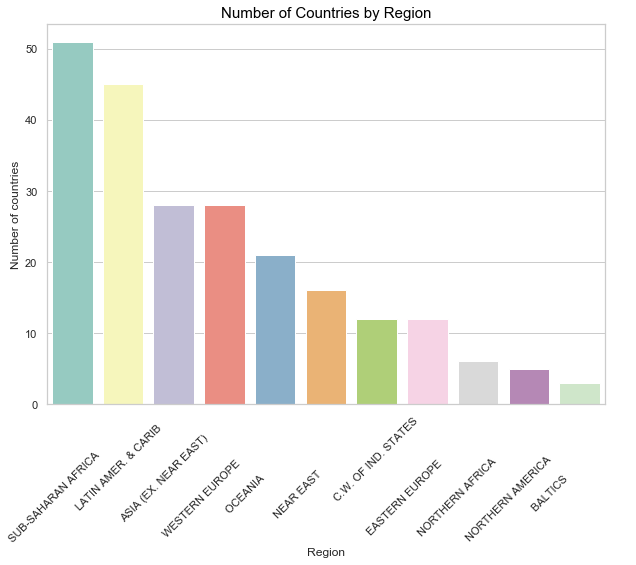

In [45]:
sns.set(style="whitegrid")

Region = df.Region.value_counts()
plt.figure(figsize=(10,7))
sns.barplot(x=Region.index,y=Region.values, palette="Set3")
plt.xticks(rotation=45)
plt.ylabel('Number of countries')
plt.xlabel('Region')
plt.title('Number of Countries by Region', color = 'black', fontsize = 15)
plt.show()

### 2. Boxplots

In [46]:
df[['GDP', 'Literacy', 'Phones']].describe()

,GDP,Literacy,Phones
count,226.000000,209.000000,223.000000
mean,9689.823009,82.838278,236.061435
std,10049.138513,19.722173,227.991829
min,500.000000,17.600000,0.200000
25%,1900.000000,70.600000,37.800000
50%,5550.000000,92.500000,176.200000
75%,15700.000000,98.000000,389.650000
max,55100.000000,100.000000,1035.600000


### Boxplots for GDP per capita , Literacy and Phones by Region

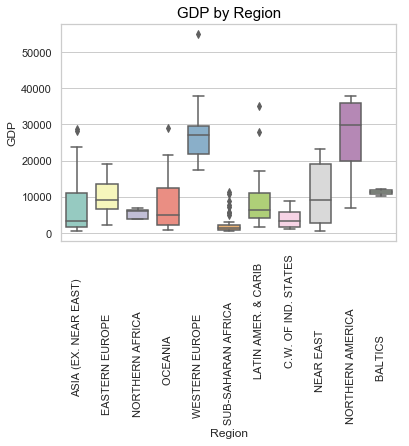

In [47]:
sns.boxplot(x="Region",y="GDP",data=df,width=0.7,palette="Set3",fliersize=5)
plt.xticks(rotation=90)
plt.title("GDP by Region",color="black", fontsize = 15)
plt.show()

In [ ]:
#This plot shows that North America has the highest GDP, variability similar to the Near East,
#but Western Europe has the largest outlier. Sub-Saharan Africa has the lowest GDP and least variability.

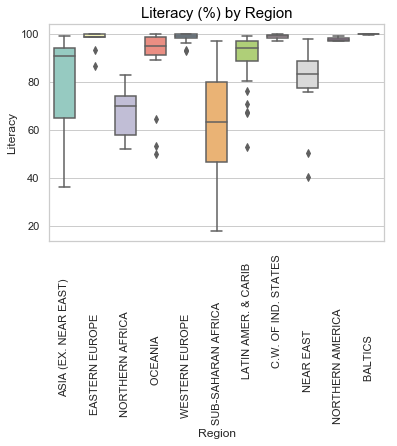

In [48]:
sns.boxplot(x="Region",y="Literacy",data=df,width=0.7,palette="Set3",fliersize=5)
plt.xticks(rotation=90)
plt.title("Literacy (%) by Region",color="black", fontsize = 15)
plt.show()

In [ ]:
#This plot shows that Sub-Saharan Africa has the lowest literacy rates and greatest variability.

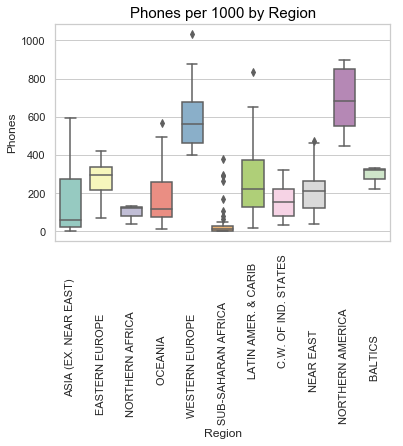

In [49]:
sns.boxplot(x="Region",y="Phones",data=df,width=0.7,palette="Set3",fliersize=5)
plt.xticks(rotation=90)
plt.title("Phones per 1000 by Region",color="black", fontsize = 15)
plt.show()

In [ ]:
#This plot clearly shows highest rates of phone ownership in North America but also the greatest variability, 
#and Western Europe has the largest outlier. The lowest rates of ownership and least variability are in Sub-Saharan Africa.

### 3. Comparing the top and bottom five countries by GDP and Literacy

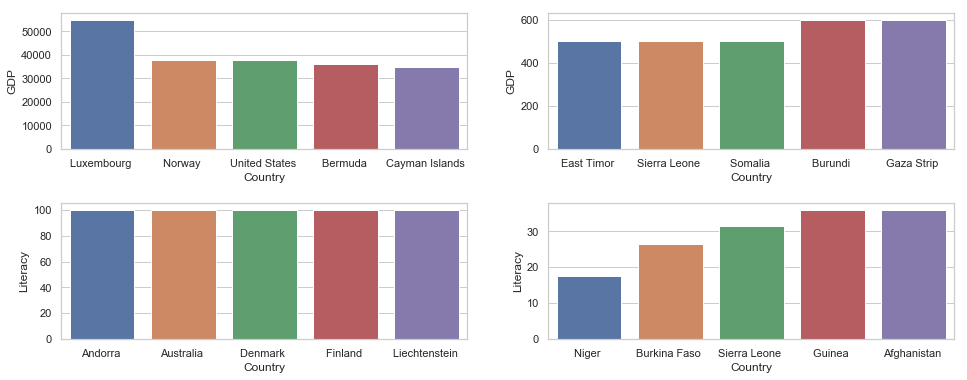

In [50]:
sns.set(style="whitegrid")
f, ax = plt.subplots(2, 2, figsize = (16,6))
plt.subplots_adjust(hspace=0.4)
k1 = sns.barplot(data = df.nlargest(5, 'GDP'), x = 'Country', y = 'GDP', ax = ax[0,0])
k2 = sns.barplot(data = df.nsmallest(5, 'GDP'), x = 'Country', y = 'GDP', ax = ax[0,1])
k3 = sns.barplot(data = df.nlargest(5, 'Literacy'), x = 'Country', y = 'Literacy', ax = ax[1,0])
k4 = sns.barplot(data = df.nsmallest(5, 'Literacy'), x = 'Country', y = 'Literacy', ax = ax[1,1])
plt.show()